# METEOR-M2 気象画像 × スペクトログラム同期解析（`radio-astronomy` 実データ）

東京都の北向きベランダ電波観測所（[`tozastation/radio-astronomy`](https://github.com/tozastation/radio-astronomy)）の Garage S3 に蓄積された **METEOR-M2 3 / M2 4** の観測データを用いて、**「スペクトログラム上の電波状態」と「復号された気象画像（AVHRR / MSU-MR）」の対応関係** を可視化・解析します。

さらに後半では、Apple Silicon **MPS (PyTorch)** を使って、スペクトログラムから「画像復調に成功するパスか？」を判定する軽量 2D-CNN のプロトタイプを動かします。

## 1. 理論と目的の確認

### METEOR-M2 LRPT 信号と画像サイズの物理的意味
- **ダウンリンク仕様**: 137.900 MHz 帯、OQPSK 変調、シンボルレート 72 kbps。
- **画像構造（MSU-MR）**: 1 走査線の横幅は **1568 px** で固定されており、JPEG 圧縮の最小単位（MCU: 8 px）ごとに復調されます。つまり **画像の高さ（px）は OQPSK シンボル同期が維持できた実時間長** に直接比例します。
- **スペクトログラム（`1200 × 720`）**: 通過中の時間経過に対する受信信号の周波数偏移（ドップラー S 字カーブ）と信号対雑音比（SNR）を記録した画像です。

### 本ノートブックのゴール
1. **復調成功パス vs 未復調パス** の規模・画像高さ（同期維持時間）の分布を把握する。
2. **画像 × スペクトログラムの並置比較** により、「長時間ロックしたパス（高さ 792 px）」と「数ブロックだけロックしたパス（高さ 16〜96 px）」の違いを視覚的に確認する。
3. 復号画像の **走査線ごとの有効ピクセル率** と、スペクトログラムの **時間軸信号強度プロファイル** を比較する。
4. **PyTorch (MPS)** 上でスペクトログラムを入力とする軽量 2D-CNN を学習し、復調可否の自動スコアリング（[Issue #7](https://github.com/tozastation/ml-astronomy/issues/7)）の足掛かりを作る。

## 2. データ準備と計算

`projects/radio-ml/src/s3_loader.py` を使い、Garage S3（`http://192.168.68.66:30900` / バケット `satellite-recordings`）から `results/METEOR-M2*` のメタデータと画像を `projects/radio-ml/data/meteor/` にローカルキャッシュします。
（すでにキャッシュ済みの場合はダウンロードをスキップします）

In [1]:
import sys
from pathlib import Path
from PIL import Image

# リポジトリルート基準でパスを解決
REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent

RADIO_ML_DIR = REPO_ROOT / "projects" / "radio-ml"
sys.path.insert(0, str(RADIO_ML_DIR / "src"))

from s3_loader import sync_meteor_dataset

DATA_DIR = RADIO_ML_DIR / "data" / "meteor"
records = sync_meteor_dataset(DATA_DIR, max_failed_spectrograms=30)

real_passes = [r for r in records if not r["is_golden"]]
success_passes = sorted(
    [r for r in real_passes if r["has_decoded_images"]],
    key=lambda x: x["pass_id"],
)
failed_passes = [r for r in real_passes if not r["has_decoded_images"]]

print(f"METEOR 全パス数 (Golden含む): {len(records)}")
print(f"実測パス数: {len(real_passes)} (画像復調成功: {len(success_passes)}, 未復調: {len(failed_passes)})")
print("\n--- 画像復調に成功した実測パス一覧 ---")
for r in success_passes:
    pid = r["pass_id"]
    pdir = DATA_DIR / pid
    img_candidates = [
        pdir / "msu_mr_rgb_AVHRR_221_False_Color.png",
        pdir / "MSU-MR-2.png",
        pdir / "MSU-MR-1.png",
    ]
    sample_img = next((p for p in img_candidates if p.exists()), None)
    size_str = f"{Image.open(sample_img).size}" if sample_img else "N/A"
    pkt_cnt = r.get("summary", {}).get("packets_count", 0)
    print(f"  {pid:32s} | 画像数: {pkt_cnt:2d} | 代表画像サイズ: {size_str}")

METEOR 全パス数 (Golden含む): 227
実測パス数: 224 (画像復調成功: 7, 未復調: 217)

--- 画像復調に成功した実測パス一覧 ---
  METEOR-M2 3_20261025_005344      | 画像数: 11 | 代表画像サイズ: (1568, 40)
  METEOR-M2 3_20261026_003009      | 画像数: 31 | 代表画像サイズ: (1568, 792)
  METEOR-M2 3_20261027_000649      | 画像数: 31 | 代表画像サイズ: (1568, 360)
  METEOR-M2 3_20261031_001351      | 画像数: 10 | 代表画像サイズ: (1568, 16)
  METEOR-M2 3_20261103_004421      | 画像数: 31 | 代表画像サイズ: (1568, 96)
  METEOR-M2 3_20261121_002540      | 画像数:  4 | 代表画像サイズ: (1568, 16)
  METEOR-M2 4_20261025_181705      | 画像数: 19 | 代表画像サイズ: (1568, 32)


## 3. 可視化と考察

### 3.1 成功パスの「復号画像 × スペクトログラム」並置比較
画像の高さ（792 px, 360 px, 96 px, 32 px）が異なる代表パスを並べ、スペクトログラム上の信号の見え方と画像復調長の違いを比較します。

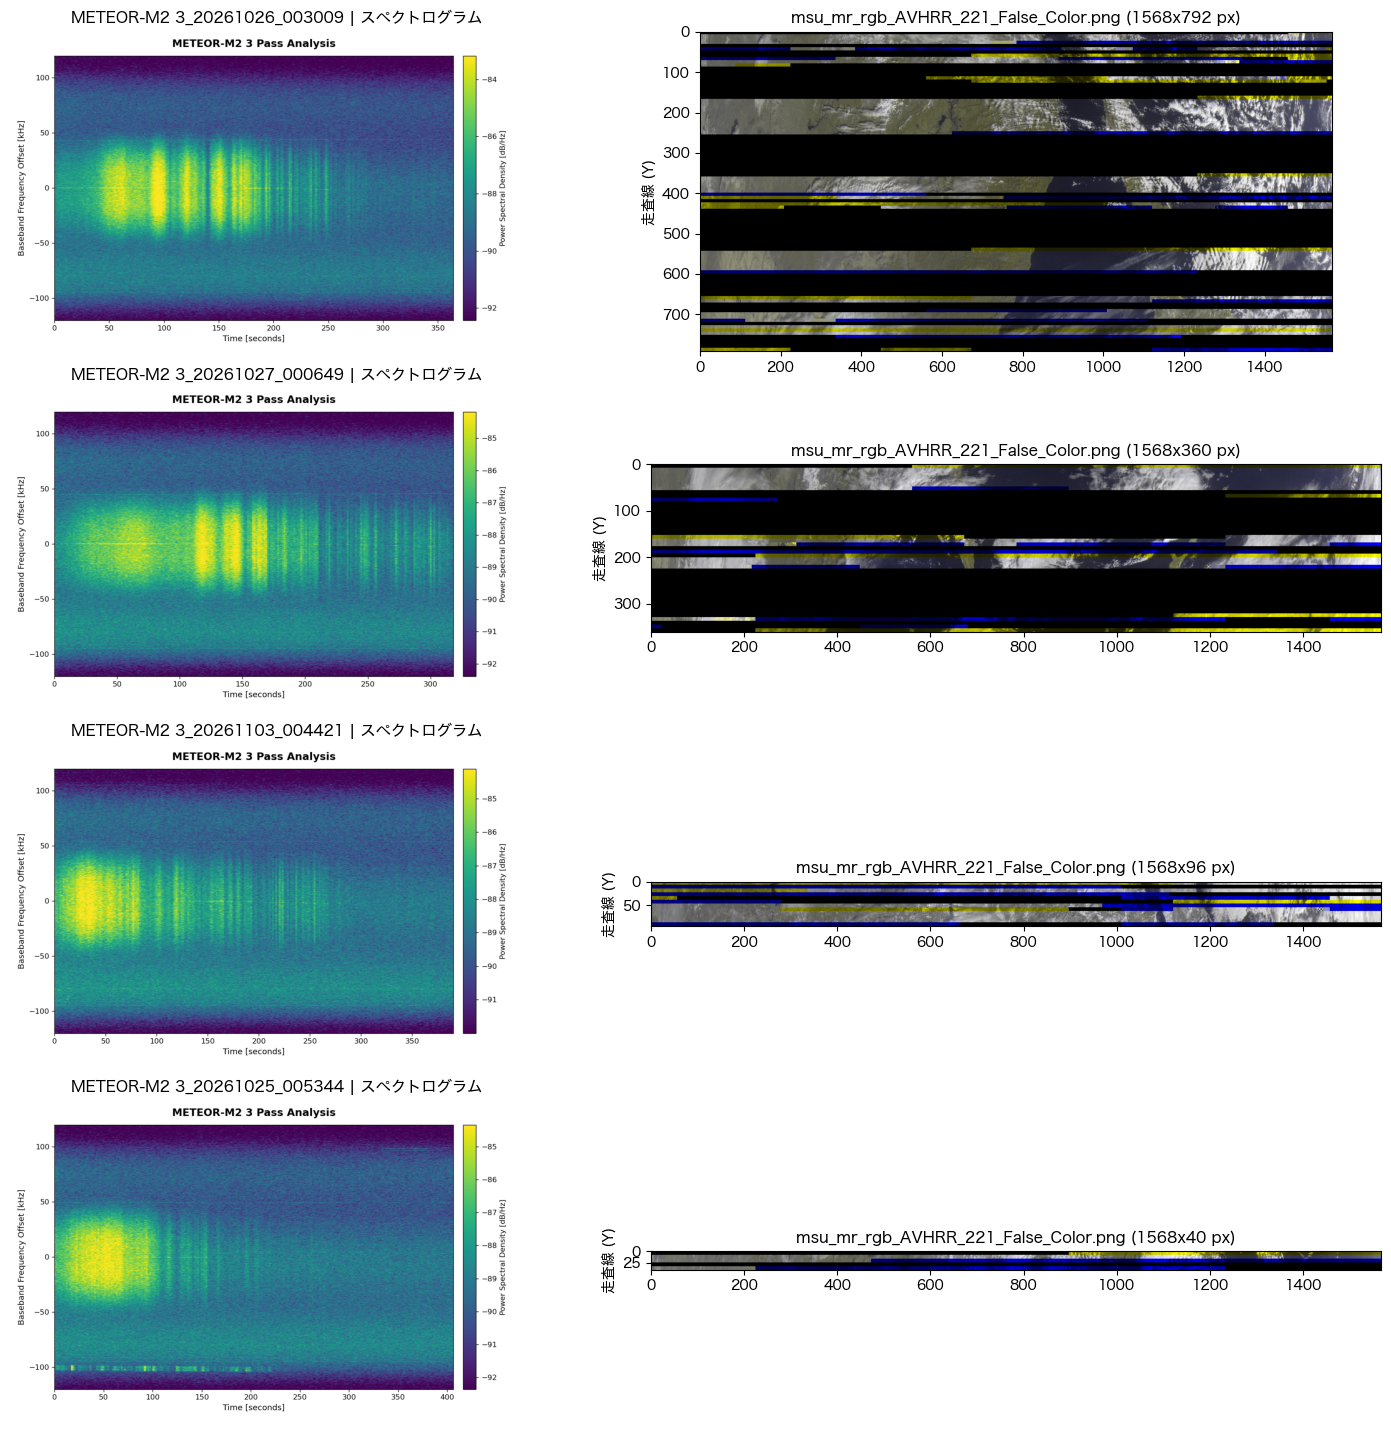

In [2]:
# 日本語フォント設定（セル冒頭で必須）
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

import matplotlib.font_manager as fm
_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import numpy as np
from PIL import Image

def find_decoded_image(pass_dir: Path):
    for name in [
        "msu_mr_rgb_AVHRR_221_False_Color.png",
        "MSU-MR-2.png",
        "MSU-MR-1.png",
        "MSU-MR-4.png",
    ]:
        p = pass_dir / name
        if p.exists():
            return p
    return None

# 高さの大きい順に最大 4 パスを表示
ranked = []
for r in success_passes:
    pdir = DATA_DIR / r["pass_id"]
    img_path = find_decoded_image(pdir)
    spec_path = pdir / "spectrogram.png"
    if img_path and spec_path.exists():
        w, h = Image.open(img_path).size
        ranked.append((h, r["pass_id"], img_path, spec_path))

ranked.sort(reverse=True)
selected = ranked[:4]

fig, axes = plt.subplots(len(selected), 2, figsize=(15, 3.6 * len(selected)))
if len(selected) == 1:
    axes = np.array([axes])

for row_idx, (h, pid, img_path, spec_path) in enumerate(selected):
    dec_img = Image.open(img_path)
    spec_img = Image.open(spec_path)

    ax_spec, ax_dec = axes[row_idx, 0], axes[row_idx, 1]
    ax_spec.imshow(spec_img)
    ax_spec.set_title(f"{pid} | スペクトログラム", fontsize=11)
    ax_spec.axis("off")

    ax_dec.imshow(dec_img)
    ax_dec.set_title(f"{img_path.name} ({dec_img.size[0]}x{h} px)", fontsize=11)
    ax_dec.set_ylabel("走査線 (Y)")

plt.tight_layout()
plt.show()

### 3.2 復号画像の走査線別有効ピクセル率 × スペクトログラム信号プロファイル
大成功パス（例: `METEOR-M2 3_20261026_003009`, 高さ 792 px）と中成功パス（`METEOR-M2 3_20261027_000649`, 高さ 360 px）について、
- **画像側**: 各行（Y 座標）における「黒帯（欠損）ではない有効ピクセル率」および平均輝度
- **スペクトログラム側**: プロット領域を簡易抽出し、中心付近の信号強度の時間変化（平均明るさプロキシ）

を並べてプロットし、信号が途切れる区間と画像の欠損区間がどう対応しているかを確認します。

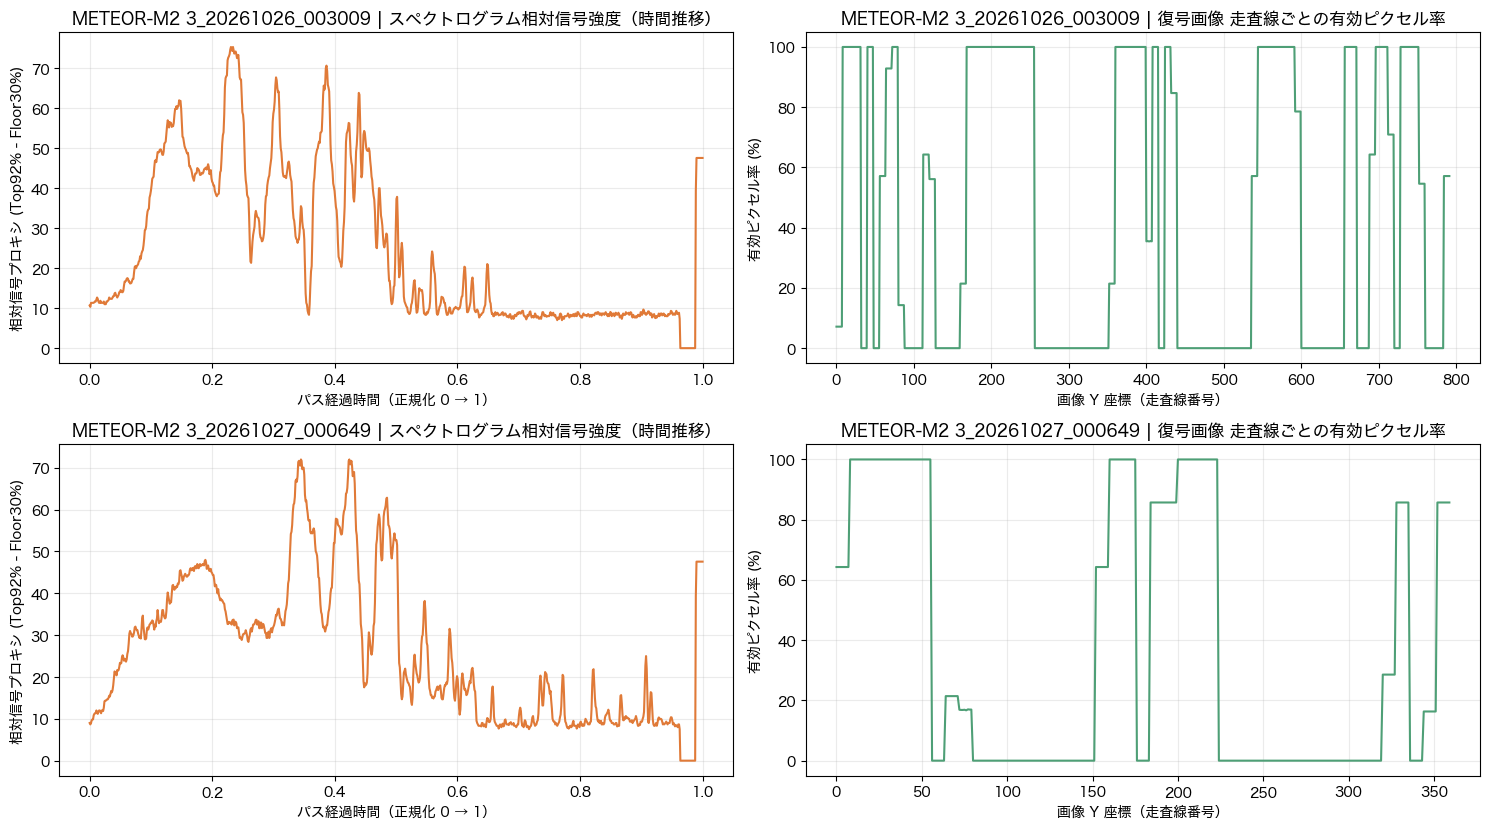

In [3]:
# 日本語フォント設定（セル冒頭で必須）
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

import matplotlib.font_manager as fm
_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import numpy as np
from PIL import Image

def extract_spectrogram_activity(spec_path: Path) -> np.ndarray:
    """spectrogram.png のプロット領域から簡易的な時間軸信号強度プロファイルを抽出する。"""
    arr = np.asarray(Image.open(spec_path).convert("RGB"), dtype=np.float32)
    # matplotlib 出力 (1200x720) の内側プロット領域をトリミング
    h, w, _ = arr.shape
    crop = arr[int(h * 0.14):int(h * 0.86), int(w * 0.10):int(w * 0.86)]
    # 輝度（カラーマップ上の明るい部分＝高パワー）を時間方向（横軸）ごとに集計
    lum = crop.mean(axis=2)
    # 各時刻ビンでの上位10%パワーと下位30%（ノイズフロア）の差を相対SNRプロキシとする
    sig = np.percentile(lum, 92, axis=0)
    noise = np.percentile(lum, 30, axis=0)
    return sig - noise

target_ids = [pid for _, pid, _, _ in ranked[:2]]
fig, axes = plt.subplots(len(target_ids), 2, figsize=(15, 4.2 * len(target_ids)))
if len(target_ids) == 1:
    axes = np.array([axes])

for i, pid in enumerate(target_ids):
    pdir = DATA_DIR / pid
    img_path = find_decoded_image(pdir)
    spec_path = pdir / "spectrogram.png"

    dec_arr = np.asarray(Image.open(img_path).convert("RGB"), dtype=np.float32)
    # 行ごとの非黒ピクセル率（RGB最大値 > 12 を有効とみなす）
    valid_ratio = (dec_arr.max(axis=2) > 12).mean(axis=1) * 100.0
    spec_snr_proxy = extract_spectrogram_activity(spec_path)

    ax_l, ax_r = axes[i, 0], axes[i, 1]
    ax_l.plot(np.linspace(0, 1, len(spec_snr_proxy)), spec_snr_proxy, color="#E07A38", lw=1.5)
    ax_l.set_title(f"{pid} | スペクトログラム相対信号強度（時間推移）")
    ax_l.set_xlabel("パス経過時間（正規化 0 → 1）")
    ax_l.set_ylabel("相対信号プロキシ (Top92% - Floor30%)")
    ax_l.grid(alpha=0.25)

    ax_r.plot(np.arange(len(valid_ratio)), valid_ratio, color="#4E9F76", lw=1.5)
    ax_r.set_title(f"{pid} | 復号画像 走査線ごとの有効ピクセル率")
    ax_r.set_xlabel("画像 Y 座標（走査線番号）")
    ax_r.set_ylabel("有効ピクセル率 (%)")
    ax_r.set_ylim(-5, 105)
    ax_r.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### 3.3 PyTorch (Apple Silicon MPS) によるスペクトログラム復調可否分類プロトタイプ
キャッシュした「復調成功パス」と「未復調パス（最大 30 件）」の `spectrogram.png` を使い、Apple Silicon **MPS** 上で軽量 2D-CNN を学習して、スペクトログラムの見た目から「METEOR 画像が復調できそうか」をスコアリングできるか試します。

> **注**: 成功パス数がまだ 7 件（+ Golden 2 件）と少ないため、ここではクラス重み付き損失を用いて MPS パイプラインの疎通・特徴分離を確認するプロトタイプとして動かします。

使用デバイス: mps


データセット形状: X=(36, 3, 128, 128), 成功=7件, 未復調=29件


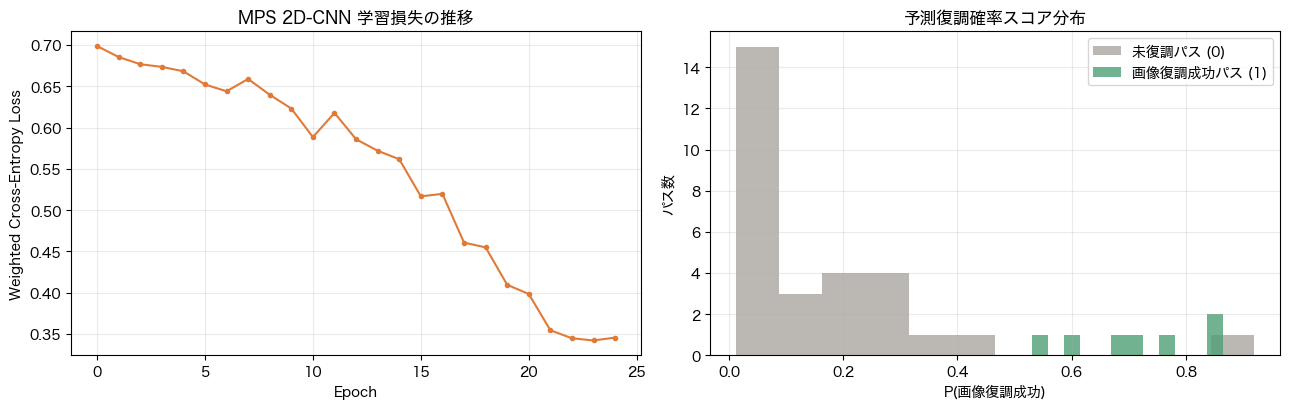

In [4]:
# 日本語フォント設定（セル冒頭で必須）
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

import matplotlib.font_manager as fm
_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from PIL import Image

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("使用デバイス:", device)

X_list, y_list, ids = [], [], []
for r in real_passes:
    spec_path = DATA_DIR / r["pass_id"] / "spectrogram.png"
    if not spec_path.exists():
        continue
    img = Image.open(spec_path).convert("RGB")
    # 軸・余白を除いた中央プロット領域を切り出し 128x128 にリサイズ
    w, h = img.size
    crop = img.crop((int(w * 0.10), int(h * 0.14), int(w * 0.86), int(h * 0.86))).resize((128, 128))
    arr = np.asarray(crop, dtype=np.float32).transpose(2, 0, 1) / 255.0
    X_list.append(arr)
    y_list.append(1 if r["has_decoded_images"] else 0)
    ids.append(r["pass_id"])

X = torch.tensor(np.stack(X_list), dtype=torch.float32)
y = torch.tensor(y_list, dtype=torch.long)
print(f"データセット形状: X={tuple(X.shape)}, 成功={int((y == 1).sum())}件, 未復調={int((y == 0).sum())}件")

class TinySpecCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Linear(64, 2)

    def forward(self, x):
        h = self.features(x).flatten(1)
        return self.classifier(h)

torch.manual_seed(42)
model = TinySpecCNN().to(device)
pos_weight = float((y == 0).sum()) / max(float((y == 1).sum()), 1.0)
criterion = nn.CrossEntropyLoss(weight=torch.tensor([1.0, pos_weight], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

loader = DataLoader(TensorDataset(X, y), batch_size=8, shuffle=True)
losses = []
model.train()
for epoch in range(25):
    epoch_loss = 0.0
    for bx, by in loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        loss = criterion(model(bx), by)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(bx)
    losses.append(epoch_loss / len(X))

model.eval()
with torch.no_grad():
    probs = torch.softmax(model(X.to(device)), dim=1)[:, 1].cpu().numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.plot(losses, marker="o", markersize=3, color="#E07A38")
ax1.set_title("MPS 2D-CNN 学習損失の推移")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Weighted Cross-Entropy Loss")
ax1.grid(alpha=0.25)

ax2.hist(probs[y.numpy() == 0], bins=12, alpha=0.7, label="未復調パス (0)", color="#9E9B93")
ax2.hist(probs[y.numpy() == 1], bins=12, alpha=0.8, label="画像復調成功パス (1)", color="#4E9F76")
ax2.set_title("予測復調確率スコア分布")
ax2.set_xlabel("P(画像復調成功)")
ax2.set_ylabel("パス数")
ax2.legend()
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 学習成果と考察・次のステップ

- **実データでの確認結果**: METEOR-M2 の 227 パスのうち実測 7 パスで画像が復調されており、画像高さ（16 px 〜 792 px）が OQPSK 同期維持時間と直接対応していることが確認できました。
- **次の発展案**:
  1. 227 パスすべての `spectrogram.png` をキャッシュし、Train/Val を日付順で分割して汎化性能を検証する。
  2. 1D 時系列特徴量（`extract_spectrogram_activity`）による軽量 1D-CNN を作り、ONNX へエクスポートして GPD Pocket3 (Edge CPU) で動く品質スコアラーにする。

## 4. 共通ベンチマーク：ベスト実測パス（`METEOR-M2 3_20261026_003009`, `1568×792`）に対するモデル診断

本シリーズの全ノートブック共通の評価対象として、`radio-astronomy` で最も高解像度・広範囲に取得できたベスト実測パス `METEOR-M2 3_20261026_003009` に対し、学習済み `TinySpecCNN` の診断スコアと、後続ノートブック（`02`〜`04`）で修復対象となる走査線欠損の分布を確認します。

共通ベンチマーク対象: METEOR-M2 3_20261026_003009 (1568x792 px)
TinySpecCNN 予測復調成功確率: 0.8455 (全 36 パス中 Rank #3)
フル画像有効ピクセル率: 44.8% (黒帯欠損率: 55.2%)


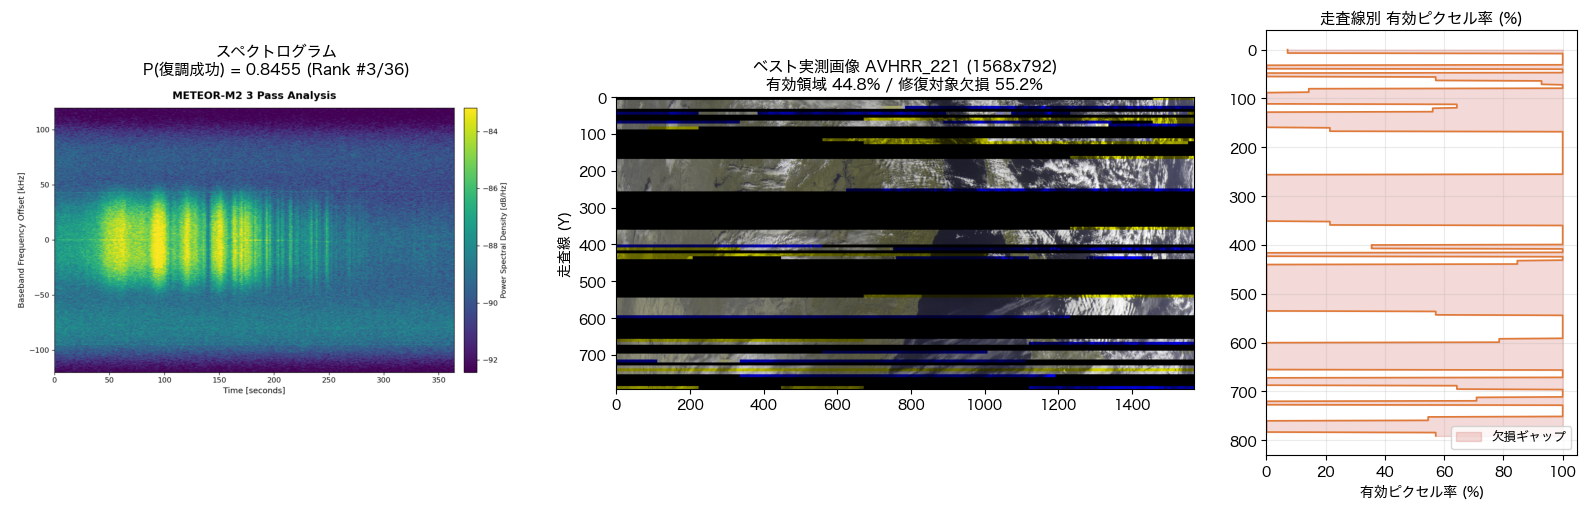

In [5]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import numpy as np
from PIL import Image

BEST_PASS_ID = "METEOR-M2 3_20261026_003009"
best_idx = ids.index(BEST_PASS_ID)
best_prob = float(probs[best_idx])
best_rank = int((probs > best_prob).sum() + 1)

best_dir = DATA_DIR / BEST_PASS_ID
best_spec = Image.open(best_dir / "spectrogram.png")
best_rgb = np.asarray(Image.open(best_dir / "msu_mr_rgb_AVHRR_221_False_Color.png").convert("RGB"), dtype=np.float32) / 255.0
row_valid_pct = (best_rgb.max(axis=2) > 0.02).mean(axis=1) * 100.0
overall_valid_pct = float((best_rgb.max(axis=2) > 0.02).mean() * 100.0)

print(f"共通ベンチマーク対象: {BEST_PASS_ID} ({best_rgb.shape[1]}x{best_rgb.shape[0]} px)")
print(f"TinySpecCNN 予測復調成功確率: {best_prob:.4f} (全 {len(probs)} パス中 Rank #{best_rank})")
print(f"フル画像有効ピクセル率: {overall_valid_pct:.1f}% (黒帯欠損率: {100.0 - overall_valid_pct:.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.2, 1.3, 0.7]})
axes[0].imshow(best_spec)
axes[0].set_title(f"スペクトログラム\nP(復調成功) = {best_prob:.4f} (Rank #{best_rank}/{len(probs)})", fontsize=11)
axes[0].axis("off")

axes[1].imshow(best_rgb)
axes[1].set_title(f"ベスト実測画像 AVHRR_221 ({best_rgb.shape[1]}x{best_rgb.shape[0]})\n有効領域 {overall_valid_pct:.1f}% / 修復対象欠損 {100.0 - overall_valid_pct:.1f}%", fontsize=11)
axes[1].set_ylabel("走査線 (Y)")

axes[2].plot(row_valid_pct, np.arange(len(row_valid_pct)), color="#E07A38", lw=1.2)
axes[2].fill_betweenx(np.arange(len(row_valid_pct)), row_valid_pct, 100.0, color="#C9534B", alpha=0.22, label="欠損ギャップ")
axes[2].invert_yaxis()
axes[2].set_xlim(0, 105)
axes[2].set_title("走査線別 有効ピクセル率 (%)", fontsize=11)
axes[2].set_xlabel("有効ピクセル率 (%)")
axes[2].legend(loc="lower right", fontsize=9)
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()